# If Oklahoma's weakest rural hospitals closed

A scenario, not a forecast. Which of Oklahoma's rural hospitals are financially weakest by one written rule, how far
people would then drive to the nearest hospital, and how full the hospitals that stay open would get.

- **The rule** uses the hospitals' own Medicare cost reports (CMS HCRIS, fiscal years 2021 to 2024): a total margin
  below zero in at least 3 of the 4 years, and a Medicaid share of charges at or above the median for rural hospitals
  across the United States. Meeting it does not mean a hospital will close.
- **Drive times** were worked out with Plotlay's drive-time engine over the U.S. Census Bureau's TIGER/Line 2024 roads,
  from every Oklahoma block group's centre of population to the nearest hospital open to everyone.
- **Beds** are HHS's weekly hospital capacity data for the last year hospitals reported (May 2023 to April 2024), or
  the cost report where HHS has nothing.

This notebook reads only `../data`. Every value is per hospital, per block group or per county: no patient-level data.

In [1]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
h = pd.read_csv(f'{DATA}/tables/hospitals.csv', dtype={'ccn': str})
b = pd.read_csv(f'{DATA}/tables/blockgroups.csv', dtype={'geoid': str})
cr = pd.read_csv(f'{DATA}/tables/cost_reports.csv', dtype={'ccn': str})
rs = pd.read_csv(f'{DATA}/tables/risk_by_state.csv')
t = pd.read_csv(f'{DATA}/tables/rural_terminations_us.csv', dtype=str)
print(len(h), 'hospitals in Oklahoma and the counties round it;', (h.state == 'OK').sum(), 'in Oklahoma')
print(len(b), 'block groups,', f'{b.population.sum():,}', 'people (ACS 2020-24)')

293 hospitals in Oklahoma and the counties round it; 103 in Oklahoma
3374 block groups, 4,028,634 people (ACS 2020-24)


## 1. The rule, state by state

`risk_by_state.csv` counts, for every state, the rural hospitals with cost reports for 2021 to 2024 (tribal and Indian
Health Service hospitals left out, their margins are not comparable) and how many meet the rule.

In [2]:
print(rs.sort_values('meets_rule', ascending=False).head(8).to_string(index=False))
print(f"United States: {rs.meets_rule.sum()} of {rs.rural_hospitals.sum()} rural hospitals meet the rule")

state  rural_hospitals  loss_3plus  meets_rule  share_meeting
   OK               79          31          20          0.253
   NY               56          16          13          0.232
   TN               54          22          12          0.222
   CA               64          13          12          0.188
   LA               61          12          12          0.197
   IN               54          12          11          0.204
   IL               84          13          10          0.119
   OR               35           9           9          0.257
United States: 212 of 2380 rural hospitals meet the rule


## 2. Oklahoma's rural hospitals

`loss_years` counts the cost reports of 2021 to 2024 with a total margin below zero; `medicaid_share` is the median
Medicaid share of charges, in per cent. The rule: `loss_years >= 3` and `medicaid_share >= 15.06`.

In [3]:
ok = h[(h.state == 'OK') & (h.rural == 'Rural')]
meets = ok[ok.in_scenario.str.startswith('Meets')]
print(f"{len(ok)} rural hospitals in Oklahoma; {len(meets)} meet the rule")
print(f"{int((ok.loss_years >= 3).sum())} lost money in 3 or more of the 4 years (tribal and IHS hospitals included)")
meets[['name', 'town', 'type', 'beds', 'patients', 'loss_years', 'medicaid_share', 'margin_2024']].sort_values('town')

74 rural hospitals in Oklahoma; 16 meet the rule
27 lost money in 3 or more of the 4 years (tribal and IHS hospitals included)


,name,town,type,beds,patients,loss_years,medicaid_share,margin_2024
103,Jackson County Memorial Hospital Authority,Altus,Short-term,36.0,21.8,3.0,18.0,-2.9
117,Pushmataha County Town of Antlers Hospital,Antlers,Short-term,15.8,7.6,3.0,25.4,-39.6
123,Hillcrest Hospital Cushing,Cushing,Short-term,19.4,6.3,4.0,25.8,-15.9
101,Great Plains Regional Medical Center,Elk City,Short-term,62.0,25.7,3.0,20.2,-11.2
181,Fairview Regional Medical Center Authority,Fairview,Critical access,25.0,2.1,3.0,15.8,-0.8
127,INTEGRIS Grove Hospital,Grove,Short-term,32.2,16.8,4.0,18.7,-0.9
136,Hillcrest Hospital Henryetta,Henryetta,Short-term,13.5,9.9,4.0,23.2,-15.0
190,Harmon Memorial Hospital,Hollis,Critical access,22.0,3.5,4.0,16.8,-1.3
124,Choctaw Memorial Hospital,Hugo,Short-term,34.0,8.0,3.0,26.5,-4.3
161,Mercy Health Love County,Marietta,Critical access,25.0,7.4,3.0,16.5,-12.4


In [4]:
# the rule again from the cost reports themselves (fiscal years 2021 to 2024)
g = cr.groupby('ccn').agg(n=('fiscal_year', 'nunique'), loss=('total_margin', lambda s: int((s < 0).sum())), med=('medicaid_share_of_charges', 'median'))
again = set(g[(g.n >= 3) & (g.loss >= 3) & (g.med >= 0.1506)].index) & set(ok[~ok.in_scenario.str.startswith('Tribal')].ccn)
print('the same 16 from the cost reports:', again == set(meets.ccn))

the same 16 from the cost reports: True


## 3. Rural hospitals that stopped inpatient care since 2005

From the CMS Provider of Services file: every rural short-term or critical access hospital whose Medicare agreement
ended since 2005, classed by what the file shows at the same place afterwards. `continued` (a new provider number, a
new owner or a change of type) is not a closure.

class
continued    413
closed       236
reh           54
reopened      34
United States: 324 rural hospitals stopped inpatient care (54 became Rural Emergency Hospitals)
                               name         city      ended    class
      USPHS CLINTON INDIAN HOSPITAL      CLINTON 2007-01-12   closed
          PAWNEE MUNICIPAL HOSPITAL       PAWNEE 2007-08-31   closed
            SEMINOLE MEDICAL CENTER     SEMINOLE 2007-09-30 reopened
        MUSKOGEE COMMUNITY HOSPITAL     MUSKOGEE 2012-07-01   closed
MEMORIAL HOSPITAL & PHYSICIAN GROUP    FREDERICK 2016-03-31   closed
                EPIC MEDICAL CENTER      EUFAULA 2016-05-24   closed
             CRAIG GENERAL HOSPITAL       VINITA 2016-12-04 reopened
           SAYRE COMMUNITY HOSPITAL        SAYRE 2017-03-08 reopened
           SAYRE COMMUNITY HOSPITAL        SAYRE 2018-08-20   closed
    LATIMER COUNTY GENERAL HOSPITAL    WILBURTON 2018-11-11   closed
    PAULS VALLEY HOSPITAL AUTHORITY PAULS VALLEY 2018-11-18 reopened
  

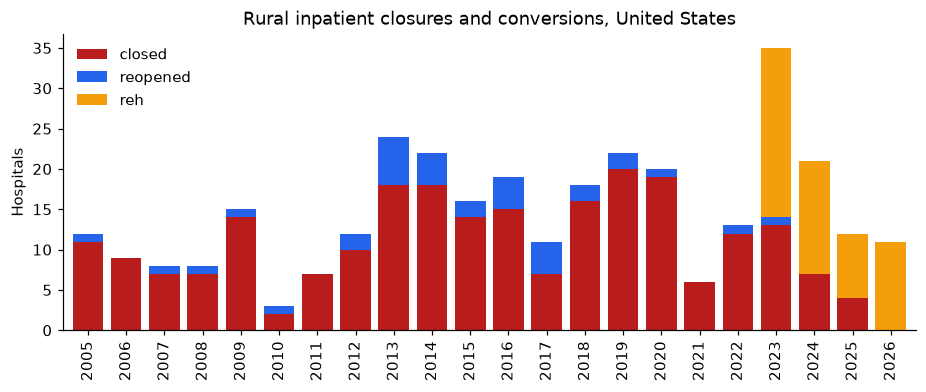

In [5]:
t['year'] = t.ended.str[:4].astype(int)
print(t['class'].value_counts().to_string())
ended = t[t['class'].isin(['closed', 'reopened', 'reh'])]
print(f"United States: {len(ended)} rural hospitals stopped inpatient care ({(ended['class'] == 'reh').sum()} became Rural Emergency Hospitals)")
print(ended[ended.state == 'OK'][['name', 'city', 'ended', 'class']].to_string(index=False))
ax = ended.groupby(['year', 'class']).size().unstack(fill_value=0)[['closed', 'reopened', 'reh']].plot.bar(stacked=True, figsize=(10, 3.5), color=['#b91c1c', '#2563eb', '#f59e0b'], width=0.8)
ax.set_xlabel(''); ax.set_ylabel('Hospitals'); ax.set_title('Rural inpatient closures and conversions, United States'); ax.legend(frameon=False)

## 4. The drive to the nearest hospital

`minutes_today` and `minutes_scenario` are the minutes from each block group's centre of population to the nearest
hospital open to everyone, today and with the 16 hospitals gone. The averages are weighted by people.

In [6]:
w = b.population
avg = lambda c, m=slice(None): np.average(b.loc[m, c], weights=w[m])
print(f"Oklahoma, the average drive: {avg('minutes_today'):.1f} min today, {avg('minutes_scenario'):.1f} min in the scenario")
r = b.rural == 'Rural'
print(f"Rural block groups ({w[r].sum():,} people): {avg('minutes_today', r):.1f} min today, {avg('minutes_scenario', r):.1f} min")
for m in (30, 45, 60): print(f"more than {m} min: {w[b.minutes_today > m].sum():>9,} today, {w[b.minutes_scenario > m].sum():>9,} in the scenario")
longer = b.minutes_added > 0.5
print(f"{w[longer].sum():,} people would drive longer, {np.average(b.minutes_added[longer], weights=w[longer]):.1f} min longer on average")

Oklahoma, the average drive: 10.7 min today, 12.8 min in the scenario
Rural block groups (1,415,721 people): 12.6 min today, 18.3 min
more than 30 min:   132,970 today,   348,649 in the scenario
more than 45 min:    11,902 today,    91,235 in the scenario
more than 60 min:     2,894 today,    16,978 in the scenario
369,390 people would drive longer, 22.8 min longer on average


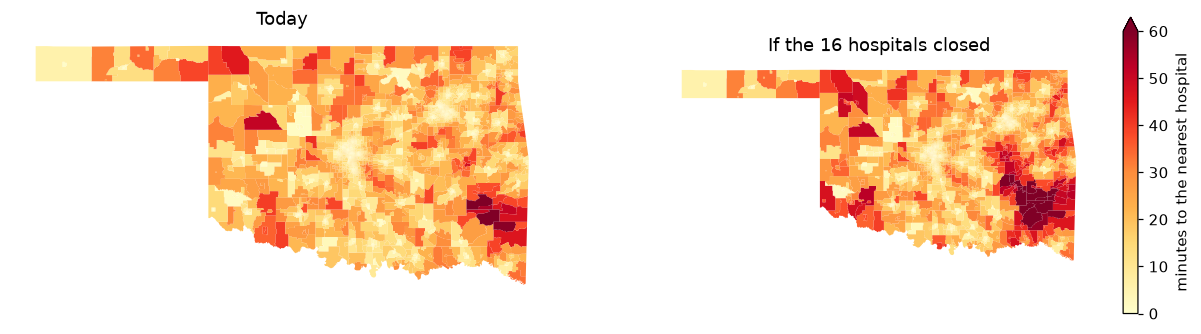

In [7]:
gb = gpd.read_file(f'{DATA}/geometry/blockgroups.geojson').merge(b, left_on='key', right_on='geoid')
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, c, title in [(ax[0], 'minutes_today', 'Today'), (ax[1], 'minutes_scenario', 'If the 16 hospitals closed')]:
    gb.plot(column=c, cmap='YlOrRd', vmin=0, vmax=60, ax=a, legend=a is ax[1], legend_kwds={'label': 'minutes to the nearest hospital', 'shrink': .7})
    a.set_axis_off(); a.set_title(title)

## 5. Counties

The counties' averages are the block groups' minutes weighted by their people (Plotlay rolls the block groups up into
the counties they stand in).

In [8]:
c = pd.read_csv(f'{DATA}/tables/counties.csv', dtype={'geoid': str})
c.sort_values('mean_min_added', ascending=False).head(8)[['name', 'population', 'mean_min_today', 'mean_min_scenario', 'over30_scenario']]

,name,population,mean_min_today,mean_min_scenario,over30_scenario
60,Pittsburg,43561,13.90,51.77,42568
63,Pushmataha,10790,21.24,58.07,10790
28,Harmon,2406,3.75,38.27,2406
76,Woodward,20158,9.32,41.04,19030
32,Jackson,24678,7.17,33.59,23351
11,Choctaw,14297,12.54,34.24,7590
4,Beckham,22148,9.18,29.31,4600
55,Okmulgee,36899,20.28,40.37,32136


## 6. Beds at the hospitals that stay open

Each closing hospital's patients (its average patients a day) are shared among the block groups nearest to it today in
proportion to their people, and each share goes to the hospital nearest that block group in the scenario
(`patient_moves.csv`, variant A). Variant B sends them to the nearest short-term general hospital instead, skipping
critical access hospitals, which keep at most 25 beds. No beds are added and nothing else changes.

In [9]:
mv = pd.read_csv(f'{DATA}/tables/patient_moves.csv', dtype={'from_ccn': str, 'to_ccn': str})
for v, col in [('A', 'occupancy_scenario'), ('B', 'occupancy_scenario_b')]:
    got = mv[mv.variant == v].groupby('to_ccn').patients_a_day.sum()
    rec = h.set_index('ccn').loc[got[got > 0.5].index]
    known = rec[rec.occupancy_today.notna()]
    print(f"Variant {v}: {len(rec)} hospitals take patients; 85% full or more: {(known.occupancy_today >= 85).sum()} today, {(known[col] >= 85).sum()} after; "
          f"100% or more: {(known.occupancy_today >= 100).sum()} today, {(known[col] >= 100).sum()} after")
a = mv[mv.variant == 'A'].groupby(['to_ccn', 'to_name']).patients_a_day.sum().sort_values(ascending=False).head(10).reset_index()
a.merge(h[['ccn', 'town', 'state', 'beds', 'occupancy_today', 'occupancy_scenario']], left_on='to_ccn', right_on='ccn').drop(columns='ccn')

Variant A: 35 hospitals take patients; 85% full or more: 4 today, 12 after; 100% or more: 1 today, 6 after
Variant B: 20 hospitals take patients; 85% full or more: 5 today, 10 after; 100% or more: 1 today, 6 after


,to_ccn,to_name,patients_a_day,town,state,beds,occupancy_today,occupancy_scenario
0,371319,"Coal County General Hospital, Inc.",29.42,Coalgate,OK,25.0,15.4,133.1
1,371330,Mangum Regional Medical Center,19.34,Mangum,OK,21.5,49.2,139.2
2,371335,"Haskell Regional Hospital, Inc",16.72,Stigler,OK,25.0,11.4,78.3
3,370245,Clinton Regional Hospital,16.54,Clinton,OK,22.0,7.0,82.1
4,040055,Baptist Health - Fort Smith,16.44,Fort Smith,AR,198.0,93.3,101.6
5,370237,"Saint Francis Hospital Vinita, Inc",13.85,Vinita,OK,15.0,47.0,139.3
6,370025,Saint Francis Hospital Muskogee,12.47,Muskogee,OK,165.0,61.6,69.2
7,450196,Paris Regional Health,11.27,Paris,TX,126.9,82.1,91.0
8,371303,Roger Mills Memorial Hospital,9.20,Cheyenne,OK,15.0,35.5,96.8
9,260001,Mercy Hospital Joplin,7.52,Joplin,MO,186.7,94.5,98.5


## Read it carefully

- **A scenario, not a forecast.** The rule picks hospitals with several years of losses and a high Medicaid share. Many
  such hospitals keep going for years with local tax support, a health system behind them or grants.
- **Closing could mean converting.** Six Oklahoma hospitals have become Rural Emergency Hospitals since 2023: emergency
  and outpatient care stay, inpatient beds go. The drive here is to a hospital with inpatient beds.
- **Speeds are averages by kind of road** (TIGER: 105 km/h interstates, 80 US and state highways, 45 local roads, 60
  ramps, 50 service drives; 20 km/h from a block group's centre to the nearest road). No traffic, no weather, roads
  both ways.
- **Patients go to the nearest hospital** in the scenario. In life they go where their doctor sends them, and some
  care (surgery, intensive care) is regional already.
- **Beds are from the last year of HHS reporting** (to April 2024) or a cost report; a hospital's beds change.
- **Tribal and Indian Health Service hospitals** are on the map but are not counted as anyone's nearest hospital.